# Matplotlib and Seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Q1. Ask the user to enter a value (e.g., M) for a mathematical function.

### - Generate x values from -10 to 10 using np.linspace().
### - Compute y values for:
    - y = M·x²
    - y = M·sin(x)
### - Plot both functions in a single figure:
    - Use different colors and line styles.
    - Add legend, grid, and title.

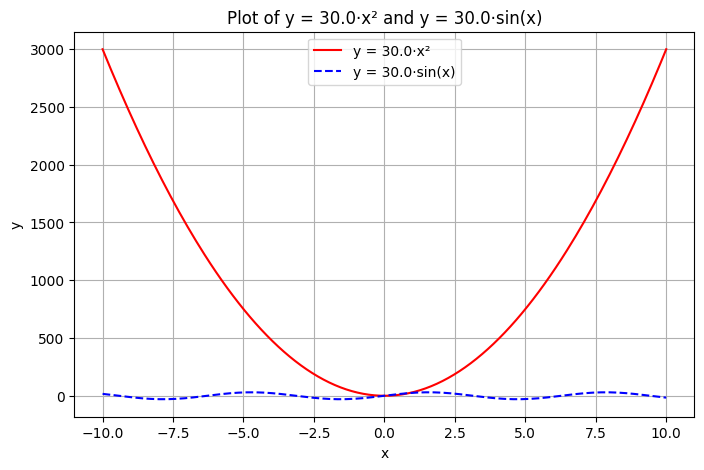

In [6]:
M = float(input("Enter value of M: "))
x = np.linspace(-10, 10, 200)
y1 = M * x**2
y2 = M * np.sin(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y1, color="red", linestyle="-", label=f"y = {M}·x²")
plt.plot(x, y2, color="blue", linestyle="--", label=f"y = {M}·sin(x)")
plt.title(f"Plot of y = {M}·x² and y = {M}·sin(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

### Q.2 Create a dataset of five subjects and scores.

#### - Convert it into a Pandas DataFrame.
#### - Plot the scores using a Seaborn bar plot with:
    - Different colors for each bar.
    - Annotations on top of each bar.
    - Title, axis labels, and grid.

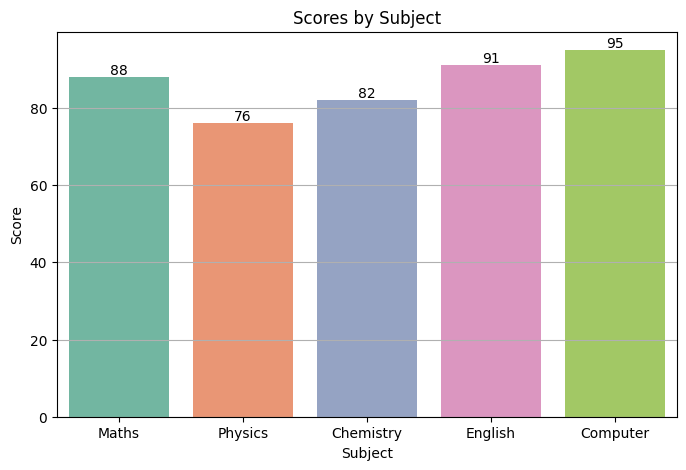

In [7]:
data = {"Subject": ["Maths", "Physics", "Chemistry", "English", "Computer"],
        "Score": [88, 76, 82, 91, 95]}
scores = pd.DataFrame(data)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x="Subject", y="Score", hue="Subject", data=scores, palette="Set2", legend=False)
for bar in ax.patches:
    ax.annotate(int(bar.get_height()), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")
plt.title("Scores by Subject")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.grid(True, axis="y")
plt.show()

### Q3. Write a Python script to select your roll number as seed for NumPy and then generate a dataset of 50 values using np.random.randn().

#### - Create a 2x2 subplot layout displaying:
    - Line plot showing cumulative sum.
    - Scatter plot with random noise.
#### - Customize with titles, axis labels, and grids.

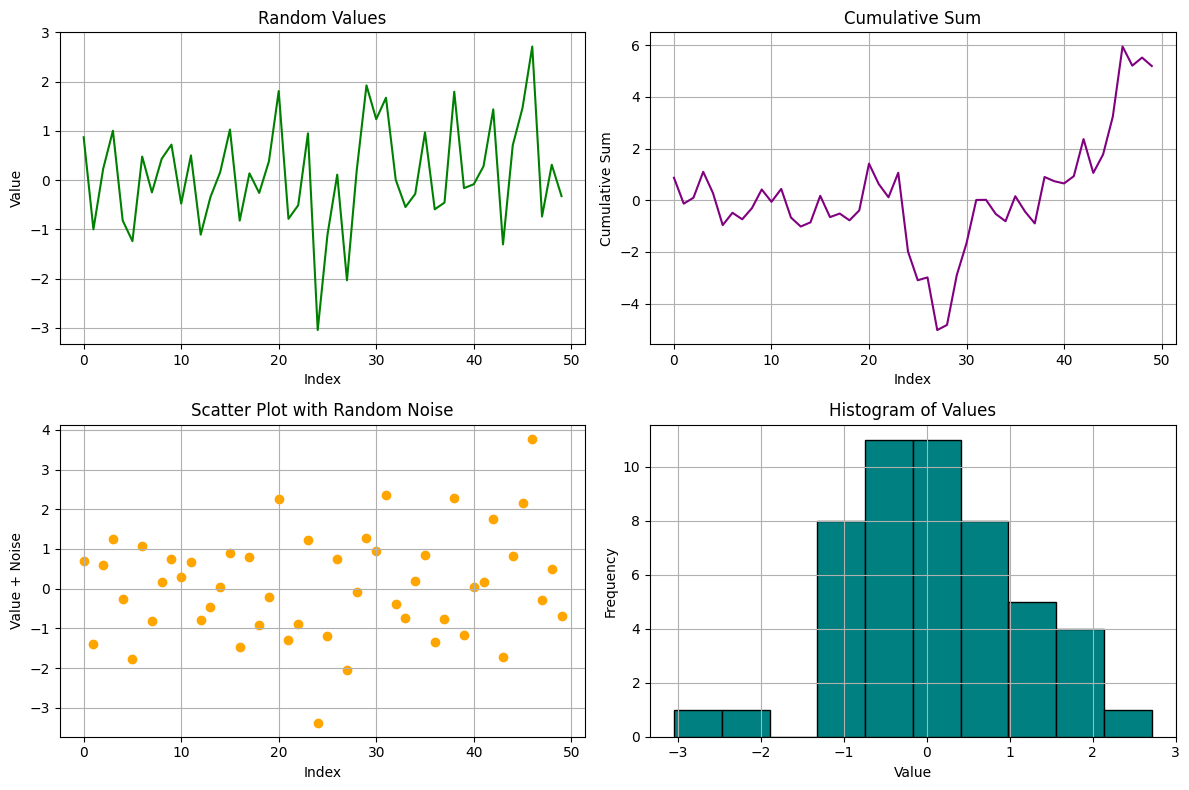

In [8]:
np.random.seed(1024170173)
values = np.random.randn(50)
idx = np.arange(50)
cumsum = np.cumsum(values)
noise = np.random.randn(50) * 0.5

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

axs[0, 0].plot(idx, values, color="green")
axs[0, 0].set_title("Random Values")
axs[0, 0].set_xlabel("Index")
axs[0, 0].set_ylabel("Value")

axs[0, 1].plot(idx, cumsum, color="purple")
axs[0, 1].set_title("Cumulative Sum")
axs[0, 1].set_xlabel("Index")
axs[0, 1].set_ylabel("Cumulative Sum")

axs[1, 0].scatter(idx, values + noise, color="orange")
axs[1, 0].set_title("Scatter Plot with Random Noise")
axs[1, 0].set_xlabel("Index")
axs[1, 0].set_ylabel("Value + Noise")

axs[1, 1].hist(values, bins=10, color="teal", edgecolor="black")
axs[1, 1].set_title("Histogram of Values")
axs[1, 1].set_xlabel("Value")
axs[1, 1].set_ylabel("Frequency")

for ax in axs.flat:
    ax.grid(True)

plt.tight_layout()
plt.show()

### Q.4 Download Data-set from the below link

https://github.com/AnjulaMehto/MCA/blob/main/company_sales_data.csv

#### Apply 'seaborn' library to do the following.

1. Read Total profit of all months and show it using a line plot.
2. Read all product sales data and show it using a multiline plot.
3. Plot bar chart for all the features/attributes.

In [9]:
url = "https://raw.githubusercontent.com/AnjulaMehto/MCA/main/company_sales_data.csv"
sales = pd.read_csv(url)
sales.head()

,month_number,facecream,facewash,toothpaste,bathingsoap,shampoo,moisturizer,total_units,total_profit
0,1,2500,1500,5200,9200,1200,1500,21100,211000
1,2,2630,1200,5100,6100,2100,1200,18330,183300
2,3,2140,1340,4550,9550,3550,1340,22470,224700
3,4,3400,1130,5870,8870,1870,1130,22270,222700
4,5,3600,1740,4560,7760,1560,1740,20960,209600


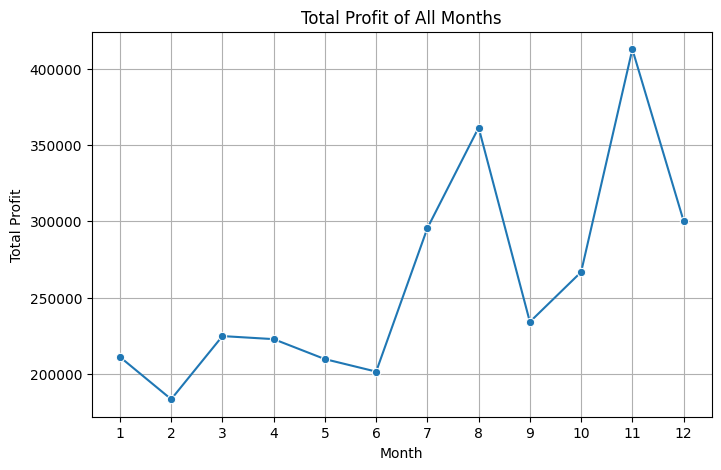

In [10]:
plt.figure(figsize=(8, 5))
sns.lineplot(x="month_number", y="total_profit", data=sales, marker="o")
plt.title("Total Profit of All Months")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(sales["month_number"])
plt.grid(True)
plt.show()

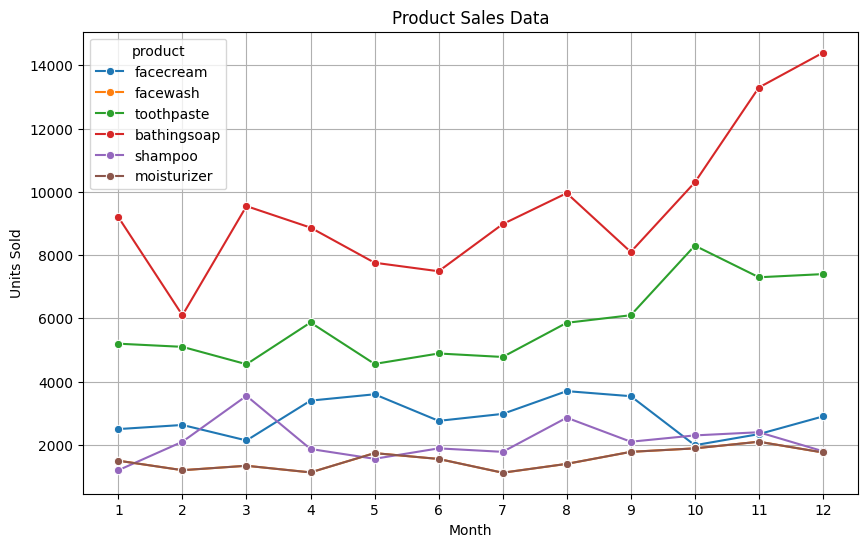

In [11]:
products = ["facecream", "facewash", "toothpaste", "bathingsoap", "shampoo", "moisturizer"]
product_sales = sales.melt(id_vars="month_number", value_vars=products,
                           var_name="product", value_name="units_sold")

plt.figure(figsize=(10, 6))
sns.lineplot(x="month_number", y="units_sold", hue="product", data=product_sales, marker="o")
plt.title("Product Sales Data")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(sales["month_number"])
plt.grid(True)
plt.show()

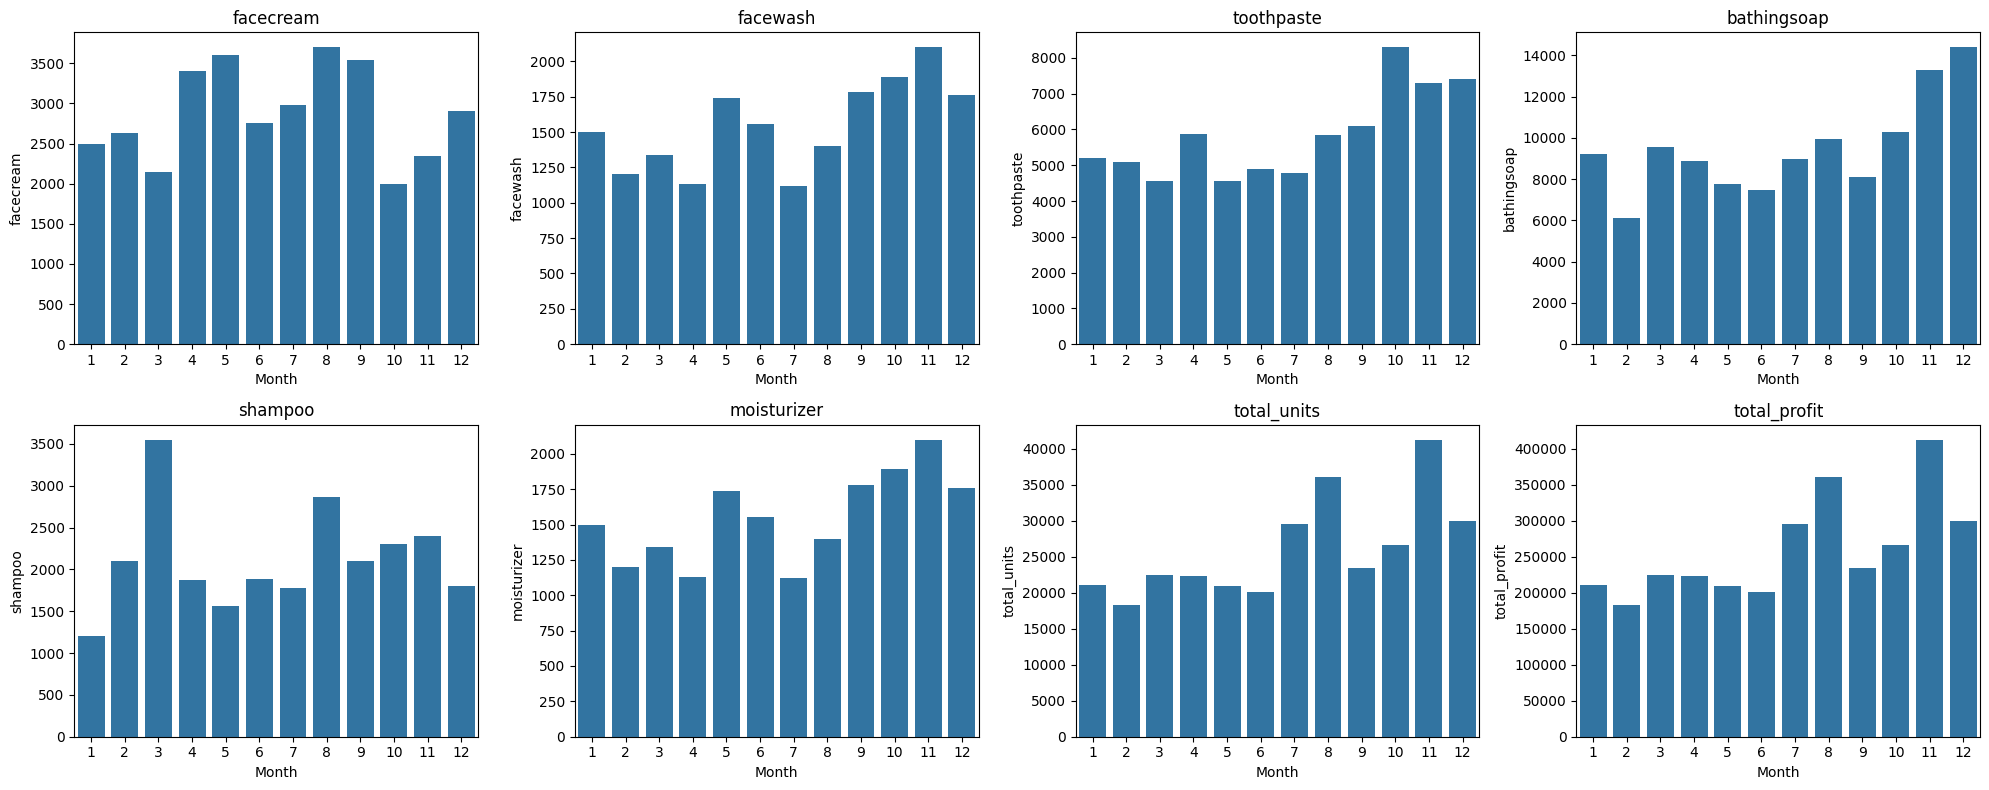

In [12]:
features = sales.columns[1:]
fig, axs = plt.subplots(2, 4, figsize=(20, 8))

for ax, col in zip(axs.flat, features):
    sns.barplot(x="month_number", y=col, data=sales, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Month")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()